# 04 Эксперименты и улучшение решения

**Автор** — Калинцев Андрей Дмитриевич  
**Проект** — подсчёт посетителей и оценка очередей по видеопотоку

## 1. Исходное решение и правила сравнения

В задании 03 трекер сопоставляет рамки при IoU от 0,30 и хранит трек до трёх пропущенных кадров. Для всех опытов берём одинаковые публичные детекции и две валидационные сцены из задания 02: MOT17-09-FRCNN и MOT20-03. Разметку читаем без изменений и берём размеченных пешеходов (mark = 1, class = 1). Обучение не требуется. Тестовые сцены оставляем для итоговой проверки.

Основная метрика — среднее IDF1 по двум сценам с равным весом. Чем выше, тем лучше. При равенстве выбираем меньшую RMSE по всем валидационным кадрам, затем оставляем более ранний вариант. MAE и RMSE показываем также для каждой сцены в людях на кадр.

В локальном протоколе IDF1 пары рамок считаются при IoU ≥ 0,50, траектории связываются глобальным взаимно однозначным назначением в пределах каждой сцены. IDF1 = 2 · IDTP / (число размеченных рамок + число предсказанных рамок). Официальный MOTChallenge дополнительно обрабатывает игнорируемые объекты, поэтому его результаты напрямую с этой таблицей не сравниваем. [Описание IDF1](https://arxiv.org/abs/1609.01775) · [Реализация TrackEval](https://github.com/JonathonLuiten/TrackEval/blob/master/trackeval/metrics/identity.py)


In [1]:
from configparser import ConfigParser
from pathlib import Path
import csv
import json

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import numpy as np
from scipy.optimize import linear_sum_assignment
from IPython.display import Markdown, display

from baseline import Tracker, box_iou

validation = {
    "MOT17-09": Path("data/MOT17/train/MOT17-09-FRCNN"),
    "MOT20-03": Path("data/MOT20/train/MOT20-03"),
}

def group_frames(rows, length):
    order = np.argsort(rows[:, 0], kind="stable")
    borders = np.searchsorted(rows[order, 0], np.arange(1, length + 2))
    return [order[left:right] for left, right in zip(borders, borders[1:])]

def load_scene(path):
    info = ConfigParser()
    info.read(path / "seqinfo.ini")
    size = info["Sequence"].getint("seqLength")
    truth = np.loadtxt(path / "gt/gt.txt", delimiter=",", ndmin=2)
    truth = truth[(truth[:, 6] == 1) & (truth[:, 7] == 1), :6]
    detections = np.loadtxt(path / "det/det.txt", delimiter=",", ndmin=2)
    valid = (np.isfinite(detections[:, :7]).all(axis=1) & (detections[:, 6] >= 0)
             & (detections[:, 4:6] > 0).all(axis=1))
    detections = detections[valid, :6]
    return {
        "path": path, "truth": truth,
        "truth_rows": group_frames(truth, size),
        "boxes": [detections[rows, 2:6] for rows in group_frames(detections, size)],
    }

scenes = {name: load_scene(path) for name, path in validation.items()}
print({name: len(scene["boxes"]) for name, scene in scenes.items()})


{'MOT17-09': 525, 'MOT20-03': 2405}


In [2]:
def predict(scene, config):
    tracker = Tracker(**config)
    track_ids = []
    for frame, boxes in enumerate(scene["boxes"], 1):
        tracks = tracker.update(frame, boxes)
        track_ids.append(np.array([key for key, _ in tracks], dtype=int))
    return track_ids

def evaluate(scene, track_ids):
    truth = scene["truth"]
    actual_ids, actual_index = np.unique(truth[:, 1], return_inverse=True)
    actual_counts = np.array([len(rows) for rows in scene["truth_rows"]])
    pred_counts = np.array([len(ids) for ids in track_ids])
    errors = pred_counts - actual_counts
    matching_gt, matching_pred = [], []

    for rows, boxes, ids in zip(scene["truth_rows"], scene["boxes"], track_ids):
        gt_rows, pred_rows = np.where(box_iou(truth[rows, 2:6], boxes) >= 0.5)
        matching_gt.append(rows[gt_rows])
        matching_pred.append(ids[pred_rows])

    gt_rows = np.concatenate(matching_gt)
    pred_ids = np.concatenate(matching_pred)
    max_id = max((int(ids.max()) for ids in track_ids if ids.size), default=0)
    hits = np.zeros((len(actual_ids), max_id + 1), dtype=int)
    np.add.at(hits, (actual_index[gt_rows], pred_ids), 1)
    rows, cols = linear_sum_assignment(hits, maximize=True)
    assignment = np.full(len(actual_ids), -1)
    assignment[rows] = cols
    correct = np.zeros(len(truth), dtype=bool)
    correct[gt_rows[assignment[actual_index[gt_rows]] == pred_ids]] = True
    idtp = int(hits[rows, cols].sum())
    assert idtp == correct.sum()
    return {
        "idf1": 2 * idtp / (actual_counts.sum() + pred_counts.sum()),
        "mae": float(np.abs(errors).mean()),
        "rmse": float(np.sqrt((errors ** 2).mean())),
        "errors": errors, "correct": correct,
    }

def run(config):
    predictions = {name: predict(scene, config) for name, scene in scenes.items()}
    metrics = {name: evaluate(scene, predictions[name]) for name, scene in scenes.items()}
    return predictions, metrics

baseline_config = {"iou_threshold": .30, "max_gap": 3}
baseline_predictions, baseline_metrics = run(baseline_config)


## 2. Анализ ошибок исходного решения

На графике отрицательная ошибка означает, что людей в разметке больше, чем в прогнозе. На кадре с ошибкой оранжевые рамки показывают детекции, зелёные — разметку. Изменение правил сопоставления может связать уже найденные рамки в более длинный трек, но при фиксированных детекциях не добавляет пропущенные рамки.


MOT17-09: недосчёт в 523 из 525 кадров, средняя ошибка со знаком -4.34
MOT20-03: недосчёт в 2405 из 2405 кадров, средняя ошибка со знаком -56.68


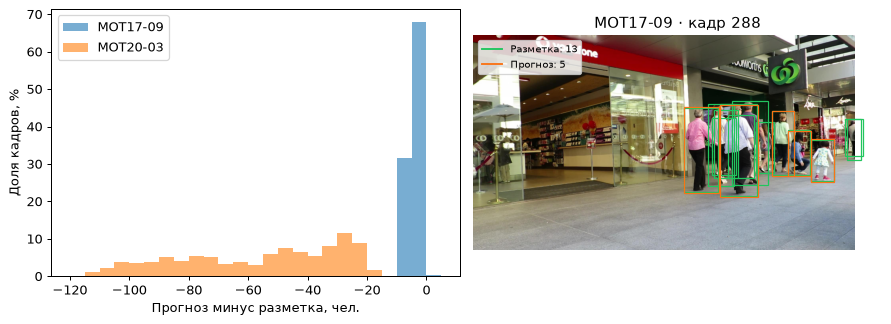

In [3]:
fig, (ax_error, ax_frame) = plt.subplots(1, 2, figsize=(10, 3.7), dpi=90)
all_errors = np.concatenate([item["errors"] for item in baseline_metrics.values()])
bins = np.arange(5 * (all_errors.min() // 5), 5 * (all_errors.max() // 5 + 1) + 1, 5)
for name, item in baseline_metrics.items():
    errors = item["errors"]
    weights = np.full(len(errors), 100 / len(errors))
    ax_error.hist(errors, bins=bins, weights=weights, alpha=.60, label=name)
    print(f"{name}: недосчёт в {(errors < 0).sum()} из {len(errors)} кадров, "
          f"средняя ошибка со знаком {errors.mean():.2f}")
ax_error.set(xlabel="Прогноз минус разметка, чел.", ylabel="Доля кадров, %")
ax_error.legend()

scene = scenes["MOT17-09"]
worst = int(np.abs(baseline_metrics["MOT17-09"]["errors"]).argmax())
actual = scene["truth"][scene["truth_rows"][worst], 2:6]
predicted = scene["boxes"][worst]
image_path = scene["path"] / "img1" / f"{worst + 1:06d}.jpg"
if image_path.exists():
    ax_frame.imshow(plt.imread(image_path))
else:
    ax_frame.set(xlim=(0, 1920), ylim=(1080, 0), aspect="equal")
for boxes, color, label in [(actual, "#22c55e", "Разметка"),
                            (predicted, "#f97316", "Прогноз")]:
    ax_frame.plot([], [], color=color, label=f"{label}: {len(boxes)}")
    for x, y, width, height in boxes:
        ax_frame.add_patch(Rectangle((x, y), width, height, fill=False, ec=color, lw=1))
ax_frame.set_title(f"MOT17-09 · кадр {worst + 1}")
ax_frame.legend(loc="upper left", fontsize=8)
ax_frame.axis("off")
fig.tight_layout()
plt.show()


## 3. Гипотезы улучшения

| Опыт | Гипотеза | Изменение относительно задания 03 | Ожидаемый эффект |
|---|---|---|---|
| H1 | При быстром перемещении или изменении рамки перекрытие падает | Порог IoU 0,20 вместо 0,30 | Меньше разрывов, возможны лишние связи между близкими людьми |
| H2 | После короткого перекрытия человек снова появляется рядом с прежней рамкой | До 8 пропущенных кадров вместо 3 | Больше восстановленных ID, возможны ошибочные связи со старыми треками |

## 4. Проверка гипотез

Каждую гипотезу проверяем отдельно. В H1 оставляем пропуск 3, в H2 сохраняем порог IoU 0,30. Для обоих вариантов вызываем функцию `run` с теми же сценами.


In [4]:
variants = {
    "Baseline": baseline_config,
    "H1": {**baseline_config, "iou_threshold": .20},
    "H2": {**baseline_config, "max_gap": 8},
}
change = {
    "Baseline": "Настройки из 03",
    "H1": "Порог IoU 0,20",
    "H2": "До 8 пропусков",
}
metrics = {"Baseline": baseline_metrics}
predictions = {"Baseline": baseline_predictions}
for name in ("H1", "H2"):
    predictions[name], metrics[name] = run(variants[name])


## 5. Общая таблица экспериментов

IDF1 выражена в процентах, разница с исходным вариантом — в процентных пунктах. MAE и RMSE приведены отдельно для обеих сцен. В CSV сохраняются вычисленные значения без округления.


| Вариант | Гипотеза и изменение | IDF1 MOT17 | IDF1 MOT20 | Средняя IDF1 | Δ IDF1 | MAE / RMSE MOT17 | MAE / RMSE MOT20 | Вывод |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Baseline | Исходный вариант, Настройки из 03 | 50.51 | 38.35 | 44.43 | +0.00 | 4.34 / 4.66 | 56.68 / 62.68 | Исходный вариант |
| H1 | Связь рамок при меньшем перекрытии, Порог IoU 0,20 | 50.51 | 38.27 | 44.39 | -0.04 | 4.34 / 4.66 | 56.68 / 62.68 | Снижение IDF1 |
| H2 | Восстановление ID после пропуска, До 8 пропусков | 51.06 | 44.38 | 47.72 | +3.29 | 4.34 / 4.66 | 56.68 / 62.68 | Рост IDF1 |

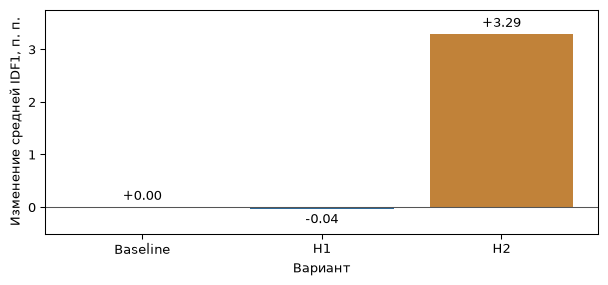

In [5]:
hypotheses = {"Baseline": "Исходный вариант", "H1": "Связь рамок при меньшем перекрытии",
              "H2": "Восстановление ID после пропуска"}
comparison = []
for name, result in metrics.items():
    a, b = result.values()
    errors = np.concatenate([a["errors"], b["errors"]])
    comparison.append({
        "variant": name, "hypothesis": hypotheses[name], "change": change[name],
        "idf1_mot17": float(100 * a["idf1"]), "idf1_mot20": float(100 * b["idf1"]),
        "idf1_mean": float(50 * (a["idf1"] + b["idf1"])),
        "mae_mot17": a["mae"], "rmse_mot17": a["rmse"],
        "mae_mot20": b["mae"], "rmse_mot20": b["rmse"],
        "rmse_all": float(np.sqrt(np.mean(errors ** 2))),
    })

header = ["Вариант", "Гипотеза и изменение", "IDF1 MOT17", "IDF1 MOT20", "Средняя IDF1",
          "Δ IDF1", "MAE / RMSE MOT17", "MAE / RMSE MOT20", "Вывод"]
lines = ["| " + " | ".join(header) + " |", "| " + " | ".join(["---"] * len(header)) + " |"]
for row in comparison:
    row["delta_idf1"] = row["idf1_mean"] - comparison[0]["idf1_mean"]
    delta = row["delta_idf1"]
    row["conclusion"] = ("Исходный вариант" if row["variant"] == "Baseline" else
                         "Рост IDF1" if delta > 0 else "Снижение IDF1" if delta < 0 else
                         "IDF1 совпала")
    lines.append(f'| {row["variant"]} | {row["hypothesis"]}, {row["change"]} | {row["idf1_mot17"]:.2f} | '
                 f'{row["idf1_mot20"]:.2f} | {row["idf1_mean"]:.2f} | {delta:+.2f} | '
                 f'{row["mae_mot17"]:.2f} / {row["rmse_mot17"]:.2f} | '
                 f'{row["mae_mot20"]:.2f} / {row["rmse_mot20"]:.2f} | {row["conclusion"]} |')
display(Markdown("\n".join(lines)))

fig, ax = plt.subplots(figsize=(6.5, 3.1), dpi=95)
bars = ax.bar([row["variant"] for row in comparison], [row["delta_idf1"] for row in comparison],
       color=["#7c8797", "#2d6a9a", "#c18239"])
ax.axhline(0, color="#555555", linewidth=.8)
ax.bar_label(bars, labels=[f'{row["delta_idf1"]:+.2f}' for row in comparison], padding=3)
ax.margins(y=.14)
ax.set(ylabel="Изменение средней IDF1, п. п.", xlabel="Вариант")
fig.tight_layout()
plt.show()


## 6. Выбор варианта и ограничения

H2 улучшил среднюю IDF1 на 3,29 п. п. Наибольший прирост получен на MOT20-03 — 6,03 п. п. Гипотеза H1 не подтвердилась: при более низком пороге средняя IDF1 снизилась на 0,04 п. п. Для каждого наблюдения из разметки сравниваем, связано ли оно с правильной траекторией при глобальном назначении. Показываем число исправленных и новых ошибок по сценам. Результат проверки очереди на реальном видео потребует размеченных событий начала ожидания и обслуживания.


In [6]:
best = max(comparison, key=lambda row: (row["idf1_mean"], -row["rmse_all"]))
name = best["variant"]
print(f'Выбран {name}: средняя IDF1 {best["idf1_mean"]:.2f}%, '
      f'изменение {best["delta_idf1"]:+.2f} п. п.')
for scene_name, scene in scenes.items():
    before = baseline_metrics[scene_name]["correct"]
    after = metrics[name][scene_name]["correct"]
    corrections = ~before & after
    regressions = before & ~after
    print(f"{scene_name}: исправлено {corrections.sum()}, новых ошибок {regressions.sum()}")
    for label, flags in [("исправление", corrections), ("новая ошибка", regressions)]:
        if flags.any():
            frame, ground_truth_id = scene["truth"][np.flatnonzero(flags)[0], :2].astype(int)
            print(f"  пример — {label}: кадр {frame}, ID разметки {ground_truth_id}")
assert all(np.array_equal(metrics[name][scene]["errors"], baseline_metrics[scene]["errors"])
           for name in variants for scene in scenes)
print("MAE и RMSE совпадают во всех опытах, поскольку набор рамок остался тем же.")


Выбран H2: средняя IDF1 47.72%, изменение +3.29 п. п.
MOT17-09: исправлено 23, новых ошибок 0
  пример — исправление: кадр 240, ID разметки 13
MOT20-03: исправлено 19820, новых ошибок 5020
  пример — исправление: кадр 843, ID разметки 2
  пример — новая ошибка: кадр 561, ID разметки 13
MAE и RMSE совпадают во всех опытах, поскольку набор рамок остался тем же.


## 7. Сохранение результата и повторный запуск

`experiment_results/experiments.csv` содержит полную таблицу, `experiment_results/tracker.json` — порог IoU и допустимый пропуск выбранного трекера. В следующей ячейке повторно читаем JSON и проверяем совпадение всех назначенных ID. Порог сопоставления при вычислении IDF1 остаётся 0,50 и хранится в ноутбуке.

Запуск на видео из корня репозитория:

```bash
.venv/bin/python baseline.py video.mp4 --tracker-config experiment_results/tracker.json --output queue.jsonl
```

Вход — MP4 и параметры зон, выход — покадровые записи JSONL. Базовые настройки задания 03 доступны при запуске без `--tracker-config`.


In [7]:
result_dir = Path("experiment_results")
result_dir.mkdir(exist_ok=True)
with (result_dir / "experiments.csv").open("w", newline="", encoding="utf-8-sig") as stream:
    writer = csv.DictWriter(stream, fieldnames=list(comparison[0]))
    writer.writeheader()
    writer.writerows(comparison)

config_path = result_dir / "tracker.json"
config_path.write_text(json.dumps(variants[best["variant"]], indent=2) + "\n", encoding="utf-8")
reloaded = json.loads(config_path.read_text(encoding="utf-8"))
for name, scene in scenes.items():
    ids = predict(scene, reloaded)
    assert all(np.array_equal(a, b) for a, b in zip(ids, predictions[best["variant"]][name], strict=True))
print("Сохранённые параметры:", reloaded)
print("Совпадение треков после повторной загрузки проверено на обеих сценах.")


Сохранённые параметры: {'iou_threshold': 0.3, 'max_gap': 8}
Совпадение треков после повторной загрузки проверено на обеих сценах.
